In [34]:
# Imports & others
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

from IPython.display import HTML

## The power iteration

An almost one-to-one implementation of the pseudocode is:

In [117]:
def rayleigh_coefficient(A: np.ndarray, v: np.ndarray) -> np.ndarray:
    """Compute the Rayleigh coefficient $R(A,v)$"""
    return v.T @ A @ v / (v.T @ v)

def power_iteration(A: np.ndarray, epsilon: float = 1e-5) -> tuple[float, list[np.ndarray]]:
    """Get th eigenvalue (with the largest abslute value) of `A`, and its corresponding eigenvector"""
    n = A.shape[0]
    b_k = np.random.rand(n)
    lambda_k = rayleigh_coefficient(A, b_k)
    vectors = [b_k]  # to keep track of vectors for visualization
    while np.linalg.norm(A @ b_k - lambda_k * b_k) > epsilon:
        b_k = A @ b_k / np.linalg.norm(A @ b_k)
        if np.isclose(np.linalg.norm(b_k), 0):
            raise Exception('b_k is zero')
        lambda_k = rayleigh_coefficient(A, b_k)
        vectors.append(b_k)
    return lambda_k, vectors

# Let's use that (matrix must be Hermitian to avoid complexes)
A = np.array([
    [1.5, .1, .3],
    [.1, -2, .2],
    [.3, .2, -1],
])
eigenvalue, eigenvectors = power_iteration(A)
print(f'The largest eigenvalue is {eigenvalue}, '
    f'corresponding to an eigenvector of {eigenvectors[-1]}, '
    f'obtained in {len(eigenvectors)} iteration(s)')

The largest eigenvalue is -2.039015120146664, corresponding to an eigenvector of [-0.01202254  0.98254107 -0.18565693], obtained in 55 iteration(s)


Let's visualize this:

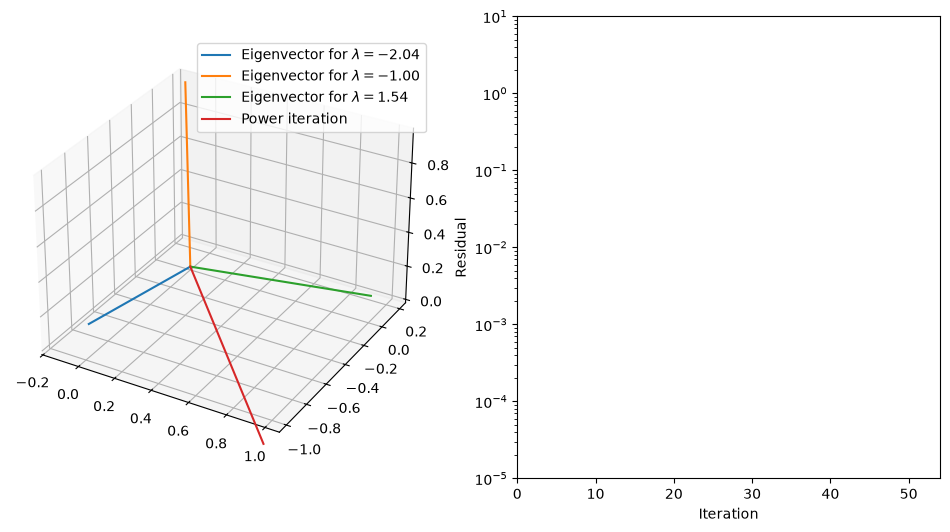

In [118]:
true_eigv, true_eigf = np.linalg.eigh(A)

fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(1, 2, 1, projection='3d')

for e, v in zip(true_eigv, true_eigf.T):
    ax.plot([0, v[0]], [0, v[1]], [0, v[2]], label=f'Eigenvector for $\\lambda={e:.2f}$')

b_k_plot = ax.plot([0, eigenvectors[0][0]], [0, eigenvectors[0][1]], [0, eigenvectors[0][2]], label='Power iteration')[0]

ax.legend()

ax2 = fig.add_subplot(1, 2, 2)
ax2.set_xlim(0, len(eigenvectors) - 1)
ax2.set_ylim(1e-5, 1e1)
ax2.set_ylabel('Residual')
ax2.set_xlabel('Iteration')

eigf_plot = ax2.semilogy([0], [np.linalg.norm(eigenvectors[-1] - eigenvectors[0])], 'o-')[0]

def update(frame):
    b_k_plot.set_xdata([0, eigenvectors[frame + 1][0]])
    b_k_plot.set_ydata([0, eigenvectors[frame + 1][1]])
    b_k_plot.set_3d_properties([0, eigenvectors[frame + 1][2]])
    
    eigf_plot.set_xdata(list(range(frame)))
    eigf_plot.set_ydata(list(np.linalg.norm(A @ v - rayleigh_coefficient(A, v) * v) for v in eigenvectors[:frame]))
    return b_k_plot

ani = animation.FuncAnimation(fig=fig, func=update, frames=len(eigenvectors) - 1, interval=500)
HTML(ani.to_html5_video())
